# Japanese Used-Car Fair Price Estimator — Professional EDA

## Business objective

This notebook prepares the dataset for a production application whose main user question is:

> **“What is my car worth in the current Japanese used-car listing market?”**

The ML target is **`vehicle_price_jpy`**, which represents the advertised vehicle price. The model is intended to estimate a **fair listing-market value**, not a guaranteed transaction price, trade-in price, auction price, or dealer purchase price.

### Intended production interaction

A user will enter a small set of vehicle attributes such as manufacturer, model, year, mileage, fuel, transmission, drivetrain, repair history, and prefecture. The backend will clean those values, engineer additional features, and send them to the model.

### What this EDA must establish

1. Whether the scraped data is suitable for this business case.
2. Which rows are trustworthy enough for training.
3. Which columns are safe to use without target leakage.
4. How Japanese categorical values should be handled.
5. Which anomalies and missing values need explicit treatment.
6. Which inputs should become part of the production feature contract.

The notebook deliberately separates **raw scraped data**, **business interpretation**, and **model-ready features**.

## 1. Environment and reproducibility

The code below imports only standard data-science packages for EDA.  
The dataset path is resolved in this place:

- `used_cars_japan.csv` in the same directory as this notebook


In [1]:
from pathlib import Path
import warnings
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Make notebook output easier to read.
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

# Resolve the dataset path in a portable way.
LOCAL_PATH = Path("data/raw/used_cars_japan.csv")

if LOCAL_PATH.exists():
    DATA_PATH = LOCAL_PATH
else:
    raise FileNotFoundError(
        "Place 'used_cars_japan.csv' next to this notebook or update DATA_PATH."
    )

print(f"Using dataset: {DATA_PATH.resolve()}")

Using dataset: /Users/mohamedaldofani/ML_Project/notebook/data/raw/used_cars_japan.csv


## 2. Load the raw scrape

`low_memory=False` is used because a few scraped columns contain mixed representations.  
We do **not** force types immediately because type inconsistency is itself a useful data-quality signal during EDA.

In [2]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Rows:    {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]:,}")
display(df_raw.head(3))

Rows:    45,042
Columns: 44


,schema_version,parser_version,source,listing_id,listing_url,collected_at,source_updated_date,title,manufacturer,model,trim,model_code,registration_year,registration_month,mileage_km,mileage_status,vehicle_price_jpy,total_price_jpy,fees_jpy,currency,price_basis,transmission,drivetrain,fuel,engine_cc,body_type,color,repair_history,shaken_expiry_month,shaken_status,prefecture,seller_name,seller_url,doors,seats,steering,one_owner,non_smoking,service_records,unused_vehicle,raw_sha256,quality_status,quality_flags,raw_attributes_json
0,1.00,2026.09.18.1,carsensor,AU0012149608,https://www.carsensor.net/usedcar/detail/AU001...,2026-09-20T07:05:34+00:00,NaN,シトロエン C5 c5ディーゼルターボ,シトロエン,C5,c5ディーゼルターボ,NaN,"2,017.00",NaN,"74,000.00",reported,"2,380,000.00","2,580,000.00","200,000.00",JPY,advertised_vehicle_price,フロア6AT,2WD,ディーゼル,"2,000.00",セダン,シルバー,False,NaN,車検残:無(購入時に新規取得) 車検の取得にあたって必要な費用(自動車重量税、自賠責保険料な...,東京都,JAVEL,https://www.carsensor.net/shop/tokyo/301244001...,4.00,5.00,右,NaN,NaN,NaN,NaN,ed9657f8970ae36df44be746a76e49db327964fcbb0eed...,ready,NaN,"{""年式(製造年)"": ""2017(H29)"", ""ワンオーナー"": ""-"", ""走行距離""..."
1,1.00,2026.09.18.1,carsensor,AU0074675938,https://www.carsensor.net/usedcar/detail/AU007...,2026-09-20T04:59:02+00:00,NaN,トヨタ センチュリー BBS20AW ローダウン 本革シート,トヨタ,センチュリー,BBS20AW ローダウン 本革シート,NaN,"2,020.00",NaN,"13,000.00",reported,NaN,NaN,NaN,JPY,advertised_vehicle_price,その他AT,2WD,ハイブリッド,"5,000.00",セダン,ブラック,False,2027-06,2027(R09)年6月,愛媛県,株式会社ASホールディングス,NaN,4.00,5.00,右,True,NaN,NaN,NaN,0852c6f39699e7ac8f1b4e2d9b7fe11a446023e510bd75...,review,missing_vehicle_price_jpy,"{""年式(初度登録年)"": ""2020(R02)"", ""ワンオーナー"": ""◯"", ""走行距..."
2,1.00,2026.09.18.1,carsensor,AU0074779083,https://www.carsensor.net/usedcar/detail/AU007...,2026-09-20T03:38:11+00:00,NaN,ダイハツ ムーヴ R TB 純正14inAW ETC メモリーナビ,ダイハツ,ムーヴ,R TB 純正14inAW ETC メモリーナビ,NaN,"2,009.00",NaN,"81,000.00",reported,"500,000.00","598,000.00","98,000.00",JPY,advertised_vehicle_price,その他AT,2WD,ガソリン,660.00,ハッチバック,グレー,False,NaN,車検残:無(購入時に新規取得) 車検の取得にあたって必要な費用(自動車重量税、自賠責保険料な...,香川県,motor7(モーターセブン),NaN,5.00,4.00,右,NaN,NaN,NaN,NaN,1baa3df81ed31a1a30159b2db678c710745f202a3e6beb...,ready,NaN,"{""年式(初度登録年)"": ""2009(H21)"", ""ワンオーナー"": ""-"", ""走行距..."


## 3. Dataset schema and high-level audit

For each column we calculate:

- pandas dtype,
- missing count and percentage,
- number of distinct non-null values.

This immediately reveals fully empty fields, high-cardinality categoricals, and fields that may require normalization.

In [3]:
schema = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_n": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values(["missing_pct", "n_unique"], ascending=[False, False])

display(schema)

,dtype,missing_n,missing_pct,n_unique
model_code,float64,45042,100.00,0
registration_month,float64,45042,100.00,0
unused_vehicle,object,44158,98.04,1
quality_flags,str,40660,90.27,7
one_owner,object,38343,85.13,1
service_records,object,36885,81.89,1
source_updated_date,str,33564,74.52,84
non_smoking,object,23181,51.47,1
shaken_expiry_month,str,20261,44.98,40
seller_url,str,10320,22.91,24628


### Important interpretation

A missing value does not always mean the same thing.

For example, fields such as `one_owner`, `non_smoking`, `service_records`, and `unused_vehicle` may be populated only when a listing explicitly advertises that property. In that situation, null often means **“not stated / unknown”**, not automatically `False`.

That distinction should be preserved in production preprocessing.

In [4]:
flag_like_columns = [
    "one_owner",
    "non_smoking",
    "service_records",
    "unused_vehicle",
    "repair_history",
]

for col in flag_like_columns:
    if col in df_raw.columns:
        print(f"\n--- {col} ---")
        display(df_raw[col].value_counts(dropna=False).head(10))


--- one_owner ---


one_owner
NaN     38343
True     6699
Name: count, dtype: int64


--- non_smoking ---


non_smoking
NaN     23181
True    21861
Name: count, dtype: int64


--- service_records ---


service_records
NaN     36885
True     8157
Name: count, dtype: int64


--- unused_vehicle ---


unused_vehicle
NaN     44158
True      884
Name: count, dtype: int64


--- repair_history ---


repair_history
False    43238
True      1804
Name: count, dtype: int64

## 4. Snapshot coverage, sources, and duplicates

This scrape is a market snapshot. Before modeling, we verify:

- which marketplaces are represented,
- the collection period,
- whether listing IDs are duplicated,
- whether raw-content hashes are duplicated.

A short snapshot is appropriate for **current-market price estimation**, but it is not enough to model time-to-sale or depreciation over time.

In [5]:
print("Source counts:")
display(df_raw["source"].value_counts(dropna=False).to_frame("rows"))

collected = pd.to_datetime(df_raw["collected_at"], errors="coerce", utc=True)
print(f"Collection start: {collected.min()}")
print(f"Collection end:   {collected.max()}")

print(f"Duplicate listing_id rows: {df_raw.duplicated('listing_id').sum():,}")
print(f"Duplicate raw_sha256 rows: {df_raw.duplicated('raw_sha256').sum():,}")

Source counts:


,rows
source,
carsensor,33564
goo-net,11478


Collection start: 2026-09-18 14:43:18+00:00
Collection end:   2026-09-21 02:14:26+00:00
Duplicate listing_id rows: 0
Duplicate raw_sha256 rows: 0


## 5. Quality-status audit

The scraper already provides `quality_status` and `quality_flags`. We treat those as useful first-pass checks, not as a complete guarantee that a row is economically plausible.

For model training, the recommended starting population is `quality_status == "ready"`, followed by additional domain validation.

In [6]:
display(df_raw["quality_status"].value_counts(dropna=False).to_frame("rows"))

print("\nMost common quality flags:")
display(df_raw["quality_flags"].value_counts(dropna=False).head(15).to_frame("rows"))

,rows
quality_status,
ready,40660
review,4382



Most common quality flags:


,rows
quality_flags,
NaN,40660
missing_vehicle_price_jpy,3909
missing_mileage_km,245
missing_mileage_km|missing_vehicle_price_jpy,203
missing_registration_year,14
missing_registration_year|missing_mileage_km,5
missing_registration_year|missing_mileage_km|missing_vehicle_price_jpy,4
missing_registration_year|missing_vehicle_price_jpy,2


## 6. Target definition and leakage checks

The production target is:

**`vehicle_price_jpy` = advertised vehicle price**

We explicitly test whether other price fields are deterministic transformations of the target.

If `total_price_jpy = vehicle_price_jpy + fees_jpy`, then using `total_price_jpy` or `fees_jpy` as model inputs would leak information unavailable to a genuine valuation model.

In [7]:
price_cols = ["vehicle_price_jpy", "fees_jpy", "total_price_jpy"]
complete_price_mask = df_raw[price_cols].notna().all(axis=1)

price_identity_error = (
    df_raw.loc[complete_price_mask, "vehicle_price_jpy"]
    + df_raw.loc[complete_price_mask, "fees_jpy"]
    - df_raw.loc[complete_price_mask, "total_price_jpy"]
)

print(f"Rows with all price components: {complete_price_mask.sum():,}")
print(f"Maximum absolute identity error: {price_identity_error.abs().max():,.0f} JPY")
print(f"Exact identity rate: {(price_identity_error == 0).mean():.2%}")

Rows with all price components: 40,924
Maximum absolute identity error: 0 JPY
Exact identity rate: 100.00%


### Leakage rule

For a model predicting `vehicle_price_jpy`, exclude:

- `total_price_jpy`
- `fees_jpy`
- raw listing titles if they may contain prices
- URLs / IDs / hashes / parser metadata
- fields generated after or from the pricing decision

The `title` field is useful for future NLP work, but should not enter Version 1 because scraped titles can literally contain a price.

In [8]:
LEAKAGE_OR_METADATA_COLUMNS = [
    "vehicle_price_jpy",  # target itself
    "total_price_jpy",
    "fees_jpy",
    "title",
    "listing_id",
    "listing_url",
    "seller_url",
    "raw_sha256",
    "raw_attributes_json",
    "schema_version",
    "parser_version",
    "quality_status",
    "quality_flags",
    "currency",
    "price_basis",
]

print("Columns intentionally excluded from the first production model:")
for col in LEAKAGE_OR_METADATA_COLUMNS:
    print(" -", col)

Columns intentionally excluded from the first production model:
 - vehicle_price_jpy
 - total_price_jpy
 - fees_jpy
 - title
 - listing_id
 - listing_url
 - seller_url
 - raw_sha256
 - raw_attributes_json
 - schema_version
 - parser_version
 - quality_status
 - quality_flags
 - currency
 - price_basis


## 7. Target distribution and price sanity checks

Used-car prices are strongly right-skewed: normal passenger cars and kei cars coexist with luxury, performance, and commercial vehicles.

We inspect both the raw price distribution and `log1p(price)`. A logarithmic view is important because a difference of ¥500,000 has very different meaning for a ¥700,000 car and a ¥20,000,000 car.

,vehicle_price_jpy
count,"40,660.00"
mean,"2,361,291.85"
std,"2,190,767.49"
min,583.00
0.1%,"109,659.00"
0.5%,"180,000.00"
1%,"221,590.00"
5%,"398,000.00"
25%,"998,000.00"
50%,"1,780,000.00"


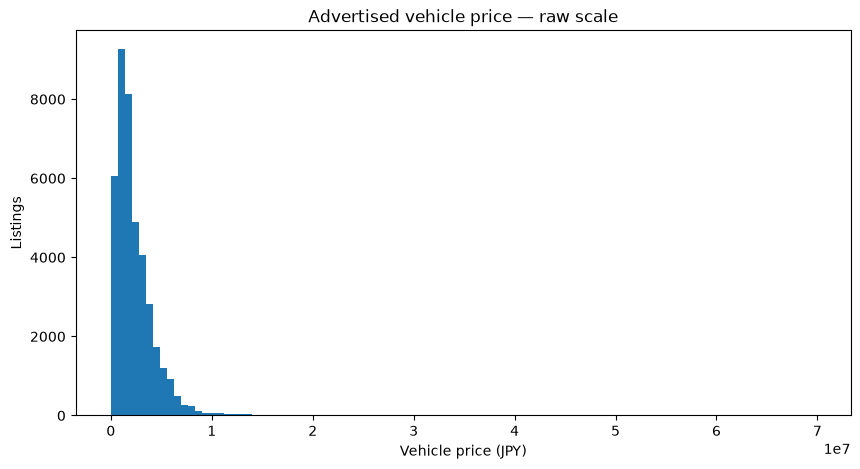

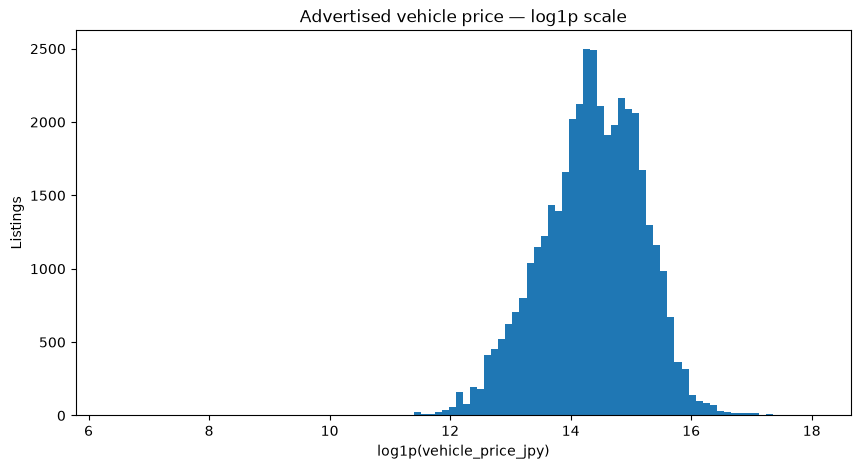

In [9]:
ready = df_raw.loc[
    (df_raw["quality_status"] == "ready")
    & df_raw["vehicle_price_jpy"].notna()
].copy()

price = ready["vehicle_price_jpy"].astype(float)

display(
    price.describe(
        percentiles=[0.001, 0.005, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.995, 0.999]
    ).to_frame("vehicle_price_jpy")
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(price, bins=100)
ax.set_title("Advertised vehicle price — raw scale")
ax.set_xlabel("Vehicle price (JPY)")
ax.set_ylabel("Listings")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(np.log1p(price), bins=100)
ax.set_title("Advertised vehicle price — log1p scale")
ax.set_xlabel("log1p(vehicle_price_jpy)")
ax.set_ylabel("Listings")
plt.show()

### Inspect suspicious extremes instead of deleting them blindly

Statistical outliers can be legitimate Ferraris, buses, trucks, or classic cars.  
The correct process is:

1. inspect the lowest/highest examples,
2. distinguish valid rare vehicles from parsing errors,
3. encode explicit validation rules,
4. document every exclusion.

The model-training notebook uses a conservative configurable lower bound (`¥30,000`) to protect against obvious parsing failures while retaining genuinely inexpensive listings.

In [10]:
columns_to_show = [
    "source",
    "title",
    "manufacturer",
    "model",
    "registration_year",
    "mileage_km",
    "vehicle_price_jpy",
    "fees_jpy",
    "total_price_jpy",
]

print("Lowest advertised prices:")
display(ready.nsmallest(15, "vehicle_price_jpy")[columns_to_show])

print("\nHighest advertised prices:")
display(ready.nlargest(15, "vehicle_price_jpy")[columns_to_show])

Lowest advertised prices:


,source,title,manufacturer,model,registration_year,mileage_km,vehicle_price_jpy,fees_jpy,total_price_jpy
1358,carsensor,メルセデス・ベンツ 190クラス 190E 2.5-16 ディーラー車,メルセデス・ベンツ,190クラス,"1,990.00","160,000.00",583.00,"5,999,417.00","6,000,000.00"
32074,carsensor,ダイハツ ムーヴコンテ 660 X 4WD 車検R9年3月3日 スマートキー キーフリー 純...,ダイハツ,ムーヴコンテ,"2,010.00","140,000.00","48,000.00","30,000.00","78,000.00"
31807,carsensor,ホンダ フィット 1.3 G ハイウェイエディション Tチェーン SDフルセグナビ Blue...,ホンダ,フィット,"2,008.00","114,000.00","50,000.00","79,000.00","129,000.00"
37311,goo-net,三菱 ミニキャブバン CD 5Fマニュアル車 2WD 両側スライドドア パワステ 運転席エア...,三菱,ミニキャブバン,"2,014.00","183,000.00","50,000.00","30,000.00","80,000.00"
36458,goo-net,"スズキ ワゴンR FX フル装備軽自動車安心保証整備車検24ヵ月付支払総額¥167,000−...",スズキ,ワゴンR,"2,011.00","74,000.00","67,000.00","100,000.00","167,000.00"
17735,carsensor,ダイハツ タント L,ダイハツ,タント,"2,009.00","148,000.00","68,000.00","60,000.00","128,000.00"
38468,goo-net,マツダ プレマシー 20S ワンオーナー買取車/社外ナビ/左側パワースライドドア/バックカメ...,マツダ,プレマシー,"2,010.00","118,000.00","69,000.00","100,000.00","169,000.00"
30662,carsensor,日産 モコ X,日産,モコ,"2,011.00","118,000.00","70,000.00","30,000.00","100,000.00"
34381,goo-net,ホンダ ライフ ハッピーエディション ユーザー様買取車/キーレス/エアコン/エアバック/パワ...,ホンダ,ライフ,"2,007.00","88,000.00","76,000.00","73,000.00","149,000.00"
32082,carsensor,ダイハツ ミラアヴィ 660 X リミテッド 4WD 走行5万キロ 車検R9年6月5日 純正...,ダイハツ,ミラアヴィ,"2,004.00","50,000.00","77,000.00","30,000.00","107,000.00"



Highest advertised prices:


,source,title,manufacturer,model,registration_year,mileage_km,vehicle_price_jpy,fees_jpy,total_price_jpy
343,carsensor,フェラーリ SF90ストラダーレ アセット フィオラノ F1 DCT E4WD レーシングシ...,フェラーリ,SF90ストラダーレ,"2,022.00",535.00,"69,800,000.00","180,000.00","69,980,000.00"
2593,carsensor,ランボルギーニ ウルス ペルフォルマンテ 左H パノラマルーフ ナイトビジョン 22AW O...,ランボルギーニ,ウルス,"2,023.00","2,000.00","45,900,000.00","510,000.00","46,410,000.00"
342,carsensor,フェラーリ F8トリブート F1 DCT レーシングシート ディーラー車 OP1185,フェラーリ,F8トリブート,"2,022.00","1,000.00","45,800,000.00","180,000.00","45,980,000.00"
16119,carsensor,フェラーリ F8スパイダー F1 DCT ボンネット内&サイドエアーインテーク・Bピラー・リ...,フェラーリ,F8スパイダー,"2,021.00","4,000.00","45,000,000.00","226,000.00","45,226,000.00"
8241,carsensor,フェラーリ F8スパイダー ロッソコルサ サスペンションリフターアダプティブフロン,フェラーリ,F8スパイダー,"2,022.00","9,000.00","42,300,000.00","280,000.00","42,580,000.00"
15336,carsensor,ポルシェ 911 GT3 PDK ヴァイザッハPKG クロノPKG フロントアクスルリフトシ...,ポルシェ,911,"2,026.00",51.00,"39,778,000.00","102,000.00","39,880,000.00"
1269,carsensor,フェラーリ フェラーリ 330GT2+2,フェラーリ,フェラーリ,"1,965.00","97,000.00","37,000,000.00","300,000.00","37,300,000.00"
1138,carsensor,フェラーリ フェラーリ 365GT2+2 英国仕様 右ハンドル,フェラーリ,フェラーリ,"1,970.00","63,000.00","36,500,000.00","300,000.00","36,800,000.00"
5294,carsensor,フェラーリ ローマスパイダー F1 DCT Ferrari認定中古車保証2年付 OP1119...,フェラーリ,ローマスパイダー,"2,024.00","4,000.00","36,000,000.00","350,000.00","36,350,000.00"
1228,carsensor,ポルシェ 356 Pre-A 1500コンチネンタル,ポルシェ,356,"1,954.00","93,000.00","35,800,000.00","200,000.00","36,000,000.00"


## 8. Numeric feature audit

We inspect values that are especially prone to scraping problems:

- registration year,
- mileage,
- engine displacement,
- seats,
- doors.

Extreme values are not automatically wrong. A 75-seat bus is possible; a 75-seat hatchback is not. Domain checks should therefore consider vehicle segment where possible.

In [11]:
numeric_cols = [
    "registration_year",
    "mileage_km",
    "engine_cc",
    "doors",
    "seats",
    "vehicle_price_jpy",
]

display(
    ready[numeric_cols].describe(
        percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
    ).T
)

,count,mean,std,min,0.1%,1%,5%,50%,95%,99%,99.9%,max
registration_year,"40,660.00","2,019.36",5.36,"1,954.00","1,986.66","2,001.00","2,011.00","2,020.00","2,026.00","2,026.00","2,026.00","2,026.00"
mileage_km,"40,660.00","48,166.38","46,658.13",2.00,3.00,5.00,10.00,"40,000.00","121,000.00","180,000.00","494,705.00","999,000.00"
engine_cc,"40,301.00","1,666.35","1,082.54",1.00,650.00,660.00,660.00,"1,500.00","3,000.00","4,600.00","9,948.30","70,000.00"
doors,"39,024.00",4.72,0.73,2.00,2.00,2.00,3.00,5.00,5.00,5.00,5.00,5.00
seats,"40,287.00",4.94,1.36,1.00,2.00,2.00,3.00,5.00,7.00,8.00,10.00,50.00
vehicle_price_jpy,"40,660.00","2,361,291.85","2,190,767.49",583.00,"109,659.00","221,590.00","398,000.00","1,780,000.00","5,899,050.00","9,457,050.00","24,073,656.00","69,800,000.00"


In [12]:
# Display a few rows with unusually large engine displacement or seating capacity.
print("Largest engine_cc values:")
display(
    ready.nlargest(15, "engine_cc")[
        ["manufacturer", "model", "body_type", "fuel", "engine_cc", "vehicle_price_jpy"]
    ]
)

print("\nLargest seat counts:")
display(
    ready.nlargest(15, "seats")[
        ["manufacturer", "model", "body_type", "seats", "vehicle_price_jpy"]
    ]
)

Largest engine_cc values:


,manufacturer,model,body_type,fuel,engine_cc,vehicle_price_jpy
10577,日産,リーフ,ハッチバック,電気,"70,000.00","615,000.00"
3466,トヨタ,MIRAI,セダン,その他,"48,000.00","3,050,000.00"
865,アバルト,アバルト500eカブリオレ,その他,電気,"47,000.00","4,730,000.00"
33449,三菱ふそう,スーパーグレート,トラック,ディーゼル,"21,200.00","7,480,000.00"
96,三菱ふそう,スーパーグレート,トラック,ディーゼル,"20,080.00","6,000,000.00"
19175,日野自動車,プロフィア,トラック,ディーゼル,"19,680.00","6,980,000.00"
914,三菱,ミニキャブミーブ,その他,電気,"16,000.00","780,000.00"
135,いすゞ,ギガ,トラック,ディーゼル,"15,680.00","14,000,000.00"
12576,いすゞ,ギガ,その他,ディーゼル,"15,680.00","6,798,000.00"
13729,いすゞ,ギガ,その他,ディーゼル,"15,680.00","27,478,000.00"



Largest seat counts:


,manufacturer,model,body_type,seats,vehicle_price_jpy
5417,マツダ,CX-30,クロカン・SUV,50.00,"2,298,000.00"
388,トヨタ,コースター,その他,29.00,"4,950,000.00"
3952,トヨタ,コースター,その他,29.00,"4,070,000.00"
5504,トヨタ,コースター,その他,29.00,"4,510,000.00"
17139,トヨタ,コースター,その他,29.00,"2,178,000.00"
23196,三菱ふそう,ローザ,その他,29.00,"2,948,000.00"
24819,三菱ふそう,ローザ,その他,29.00,"2,618,000.00"
28591,三菱ふそう,ローザ,その他,26.00,"2,618,000.00"
11069,トヨタ,コースター,その他,24.00,"6,200,000.00"
9416,日産,NV350キャラバン,その他,16.00,"1,540,000.00"


## 9. Missingness analysis

Missingness itself can carry information, but production behavior must be intentional.

For the app:

- mandatory fields should be validated before prediction,
- optional fields should map to an explicit `__UNKNOWN__` category,
- we should never silently convert “not stated” into `False`.

,missing_pct
model_code,100.00
registration_month,100.00
unused_vehicle,98.04
quality_flags,90.27
one_owner,85.13
service_records,81.89
source_updated_date,74.52
non_smoking,51.47
shaken_expiry_month,44.98
seller_url,22.91


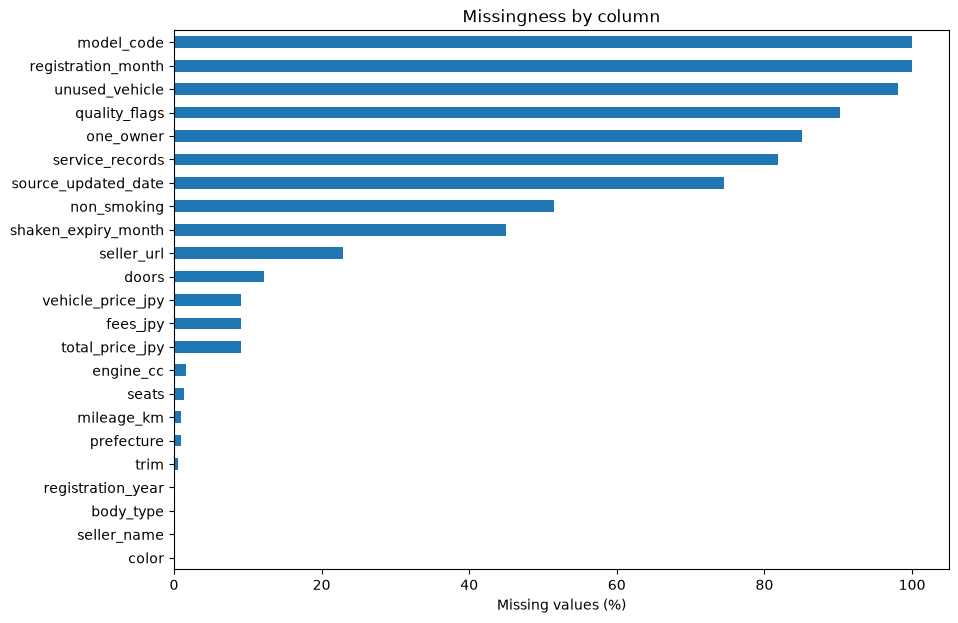

In [13]:
missing = (
    df_raw.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_pct")
)

display(missing.to_frame())

fig, ax = plt.subplots(figsize=(10, 7))
missing[missing > 0].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Missingness by column")
ax.set_xlabel("Missing values (%)")
plt.show()

## 10. Cardinality analysis

CatBoost is a strong candidate because this dataset contains many high-cardinality categorical fields such as model, trim, seller, and color.

However, the production model should use only fields that are either:

- entered by the user,
- reliably inferred from user choices, or
- supplied by a trusted backend enrichment service.

We intentionally avoid `seller_name` in the first model because a person asking “what is my car worth?” should not need to choose a dealer.

In [14]:
categorical_cols = df_raw.select_dtypes(include=["object"]).columns.tolist()

cardinality = (
    df_raw[categorical_cols]
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .rename("n_unique")
)

display(cardinality.to_frame())

/var/folders/jr/774359wn5tg3ddwfx4sd5y5r0000gn/T/ipykernel_49739/5898467.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_raw.select_dtypes(include=["object"]).columns.tolist()


,n_unique
raw_sha256,45042
listing_id,45042
listing_url,45042
raw_attributes_json,45039
collected_at,44867
title,39444
seller_url,24628
trim,8006
seller_name,4091
color,3711


## 11. normalize Japanese text strategy

The model does **not** need Japanese categories translated into English.  
For example, CatBoost can treat `トヨタ` and `アルファード` as valid categorical tokens.

The important requirement is **consistency**.

so we will do this approach:

- keep the original Japanese value for traceability,
- Unicode-normalize and clean whitespace,
- create canonical features for categories with obvious synonyms,
- optionally create English labels only for UI/display.

For example, `ディーゼル` and `軽油` should both map to a canonical `diesel` category.

In [15]:
def normalize_text(value):
    """Normalize scraped categorical text without changing its semantic identity."""
    if pd.isna(value):
        return "__UNKNOWN__"

    text = unicodedata.normalize("NFKC", str(value)).strip()
    text = re.sub(r"\s+", " ", text)

    placeholders = {"", "-", "−", "'-", "不明", "nan", "None"}
    return "__UNKNOWN__" if text in placeholders else text


def normalize_fuel(value):
    """Collapse Japanese fuel synonyms into stable machine categories."""
    text = normalize_text(value)

    if text == "__UNKNOWN__":
        return text
    if "プラグイン" in text and "ハイブリッド" in text:
        return "phev"
    if "電気" in text or "EV" in text.upper():
        return "electric"
    if "ディーゼル" in text or "軽油" in text:
        return "diesel"
    if "ハイブリッド" in text:
        return "hybrid"
    if "ガソリン" in text:
        return "gasoline"
    if "水素" in text:
        return "hydrogen"
    return "other"


fuel_example = (
    df_raw[["fuel"]]
    .drop_duplicates()
    .assign(fuel_clean=lambda x: x["fuel"].map(normalize_fuel))
    .sort_values(["fuel_clean", "fuel"])
)

display(fuel_example)

,fuel,fuel_clean
4192,'-,__UNKNOWN__
0,ディーゼル,diesel
33601,軽油,diesel
47,電気,electric
33573,電気自動車(EV),electric
2,ガソリン,gasoline
1,ハイブリッド,hybrid
44940,水素,hydrogen
311,その他,other
33688,プラグインハイブリッド,phev


## 12. Transmission engineering

The raw transmission column contains detailed Japanese strings such as shifter location, manual mode, gear count, CVT, AT, and MT.

For production we can preserve the raw string while extracting simpler derived features:

- simplified transmission family,
- number of gears when stated,
- whether an automatic transmission advertises manual mode.

This reduces fragmentation while retaining useful information.

In [16]:
def normalize_transmission(value):
    """Map many scraped transmission descriptions into stable families."""
    text = normalize_text(value).upper()

    if text == "__UNKNOWN__":
        return text
    if "CVT" in text:
        return "CVT"
    if "DCT" in text:
        return "DCT"
    # Check AT before generic MT because 'MTモード付AT' is still an automatic.
    if "AT" in text:
        return "AT"
    if "MT" in text:
        return "MT"
    return "other"


def extract_gear_count(value):
    """Extract values such as 6 from '6AT', '6MT', or Japanese '6速'."""
    text = normalize_text(value).upper()

    if text == "__UNKNOWN__":
        return np.nan

    match = re.search(r"(\d+)\s*(?:AT|MT|速)", text)
    return float(match.group(1)) if match else np.nan


transmission_example = (
    df_raw["transmission"]
    .value_counts(dropna=False)
    .head(30)
    .rename_axis("transmission")
    .reset_index(name="rows")
)

transmission_example["transmission_simple"] = transmission_example["transmission"].map(
    normalize_transmission
)
transmission_example["gear_count"] = transmission_example["transmission"].map(
    extract_gear_count
)

display(transmission_example)

,transmission,rows,transmission_simple,gear_count
0,インパネCVT,8553,CVT,NaN
1,インパネAT,4297,AT,NaN
2,CVT,4136,CVT,NaN
3,その他AT,3601,AT,NaN
4,フロアCVT,3501,CVT,NaN
5,フロアMTモード付CVT,2323,CVT,NaN
6,フロア6MT,2011,MT,6.00
7,フロアMTモード付6AT,1551,AT,6.00
8,インパネMTモード付CVT,1213,CVT,NaN
9,フロアMTモード付8AT,1208,AT,8.00


## 13. Relationship between price, age, and mileage

These are expected to be among the strongest predictors.

We derive:

- `vehicle_age`: years between the market snapshot and registration year,
- `log_mileage`: stabilizes the heavily skewed mileage distribution,
- `km_per_year`: distinguishes a young high-mileage car from an old low-mileage car.

Because this snapshot is from 2026, the exploratory reference year is 2026.  
The trained model should be retrained as the market moves forward rather than assumed to remain permanently valid.

In [17]:
EDA_REFERENCE_YEAR = int(collected.dt.year.mode().iloc[0])

eda = ready.copy()
eda["vehicle_age"] = (
    EDA_REFERENCE_YEAR - pd.to_numeric(eda["registration_year"], errors="coerce")
).clip(lower=0)

eda["mileage_km"] = pd.to_numeric(eda["mileage_km"], errors="coerce")
eda["log_mileage"] = np.log1p(eda["mileage_km"].clip(lower=0))
eda["km_per_year"] = eda["mileage_km"] / eda["vehicle_age"].clip(lower=1)

print(f"EDA reference year: {EDA_REFERENCE_YEAR}")
display(
    eda[["vehicle_age", "mileage_km", "log_mileage", "km_per_year"]]
    .describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
    .T
)

EDA reference year: 2026


,count,mean,std,min,1%,5%,50%,95%,99%,max
vehicle_age,"40,660.00",6.64,5.36,0.00,0.00,0.00,6.00,15.00,25.00,72.00
mileage_km,"40,660.00","48,166.38","46,658.13",2.00,5.00,10.00,"40,000.00","121,000.00","180,000.00","999,000.00"
log_mileage,"40,660.00",9.80,2.42,1.10,1.79,2.40,10.60,11.70,12.10,13.81
km_per_year,"40,660.00","7,177.13","5,629.27",1.00,5.00,10.00,"6,500.00","16,285.71","24,238.65","249,750.00"


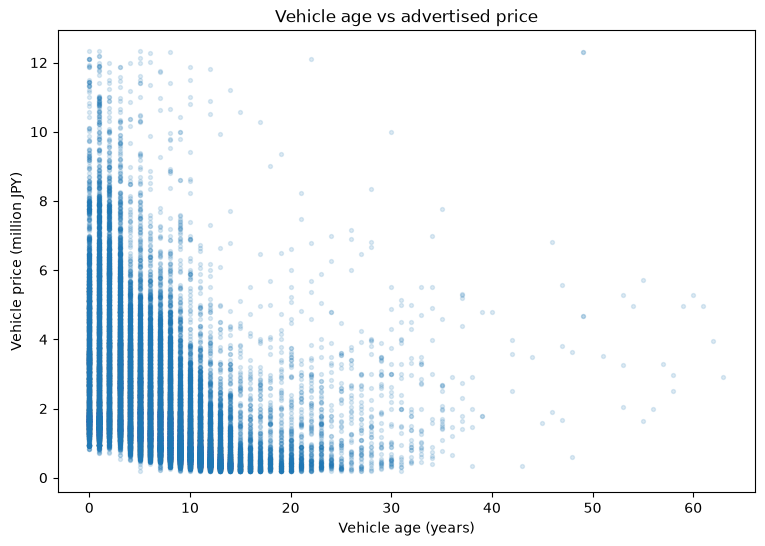

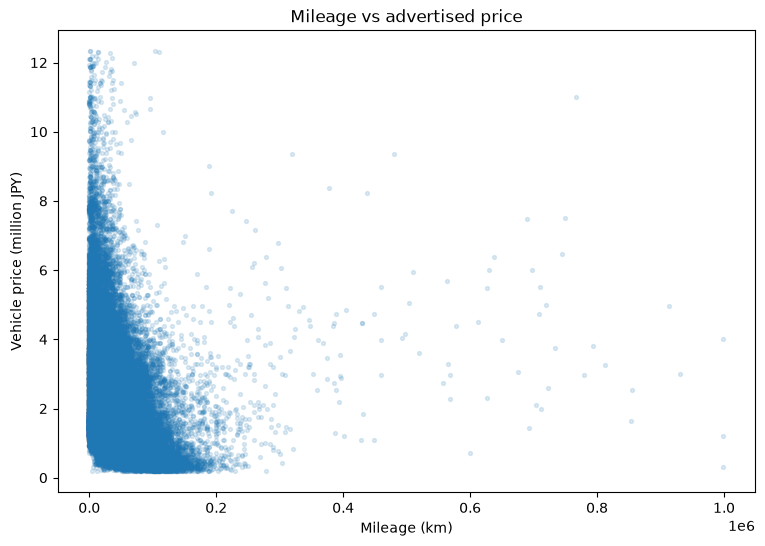

In [18]:
# To avoid a few extreme vehicles visually flattening the plots,
# the charts use only the central 99% of the relevant variables.
plot_df = eda[
    eda["vehicle_price_jpy"].between(
        eda["vehicle_price_jpy"].quantile(0.005),
        eda["vehicle_price_jpy"].quantile(0.995),
    )
].copy()

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    plot_df["vehicle_age"],
    plot_df["vehicle_price_jpy"] / 1_000_000,
    s=8,
    alpha=0.15,
)
ax.set_title("Vehicle age vs advertised price")
ax.set_xlabel("Vehicle age (years)")
ax.set_ylabel("Vehicle price (million JPY)")
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    plot_df["mileage_km"],
    plot_df["vehicle_price_jpy"] / 1_000_000,
    s=8,
    alpha=0.15,
)
ax.set_title("Mileage vs advertised price")
ax.set_xlabel("Mileage (km)")
ax.set_ylabel("Vehicle price (million JPY)")
plt.show()

## 14. Categorical market structure

A raw average price by manufacturer or model is **descriptive**, not causal.  
Different brands have different model mixes, years, mileage, and vehicle segments.

For each category, it is more informative to display:

- listing count,
- median price,
- median registration year,
- median mileage.

The median is used because used-car price distributions are highly skewed.

In [19]:
def category_summary(data, column, min_count=30, top_n=25):
    """Summarize category size and typical vehicle characteristics."""
    summary = (
        data.groupby(column, dropna=False)
        .agg(
            listings=("vehicle_price_jpy", "size"),
            median_price_jpy=("vehicle_price_jpy", "median"),
            median_year=("registration_year", "median"),
            median_mileage_km=("mileage_km", "median"),
        )
        .query("listings >= @min_count")
        .sort_values("listings", ascending=False)
        .head(top_n)
    )
    return summary


for col in ["manufacturer", "model", "fuel", "body_type", "drivetrain", "prefecture"]:
    print(f"\n### {col}")
    display(category_summary(eda, col))


### manufacturer


,listings,median_price_jpy,median_year,median_mileage_km
manufacturer,,,,
トヨタ,11736,"2,788,000.00","2,021.00","37,000.00"
ホンダ,5011,"1,449,000.00","2,020.00","39,000.00"
スズキ,4503,"1,213,000.00","2,021.00","34,000.00"
日産,4245,"1,234,000.00","2,019.00","47,000.00"
ダイハツ,3846,"940,000.00","2,019.00","43,000.00"
マツダ,1986,"1,790,000.00","2,020.00","47,000.00"
スバル,1558,"1,674,000.00","2,018.00","51,500.00"
レクサス,1544,"3,806,000.00","2,019.00","43,000.00"
三菱,1254,"1,789,500.00","2,022.00","29,000.00"



### model


,listings,median_price_jpy,median_year,median_mileage_km
model,,,,
タント,951,"980,000.00","2,019.00","47,000.00"
アルファード,879,"4,133,000.00","2,021.00","37,000.00"
N-BOX,876,"1,057,500.00","2,019.00","46,000.00"
プリウス,870,"1,859,500.00","2,019.00","45,000.00"
セレナ,824,"1,829,000.00","2,019.00","51,000.00"
ハイエースバン,727,"4,200,000.00","2,023.00","26,000.00"
ハスラー,696,"1,250,500.00","2,021.00","30,000.00"
スペーシア,690,"1,209,000.00","2,022.00","27,000.00"
シエンタ,646,"2,252,500.00","2,022.00","31,000.00"



### fuel


...

,listings,median_price_jpy,median_year,median_mileage_km
body_type,,,,
ハッチバック,12072,"1,030,000.00","2,019.00","45,000.00"
クロカン・SUV,7787,"2,677,000.00","2,022.00","30,000.00"
ミニバン,4468,"2,889,000.00","2,021.00","40,000.00"
セダン,3001,"2,380,000.00","2,018.00","53,000.00"
SUV・クロスカントリー・ライトクロカン,2620,"2,970,500.00","2,022.00","31,000.00"
軽-RV系,2617,"1,280,000.00","2,021.00","28,000.00"
ミニバン・ワンボックス,2291,"2,666,000.00","2,021.00","41,000.00"
その他,1304,"780,000.00","2,015.00","87,000.00"
トラック,878,"1,399,000.00","2,015.00","75,000.00"



### drivetrain


,listings,median_price_jpy,median_year,median_mileage_km
drivetrain,,,,
2WD,30112,"1,580,000.00","2,020.00","42,000.00"
4WD,10548,"2,806,000.00","2,021.00","34,000.00"



### prefecture


,listings,median_price_jpy,median_year,median_mileage_km
prefecture,,,,
愛知県,6251,"2,201,000.00","2,021.00","29,000.00"
沖縄県,3914,"770,000.00","2,017.00","79,000.00"
大阪府,3234,"2,497,500.00","2,021.00","30,000.00"
埼玉県,2987,"1,996,000.00","2,019.00","43,000.00"
千葉県,1930,"2,398,000.00","2,020.00","38,000.00"
北海道,1868,"2,100,000.00","2,020.00","46,000.00"
神奈川県,1650,"2,801,000.00","2,022.00","23,000.00"
福岡県,1464,"1,939,500.00","2,021.00","37,500.00"
東京都,1458,"2,399,000.00","2,023.00","15,000.00"


## 15. Marketplace/source bias

CarSensor and Goo-net may contain different inventory mixes.  
A direct source-level price difference does **not** prove that one marketplace is more expensive.

We first compare descriptive medians, then inspect model-year groups that occur on both sources. Source is useful for diagnostics, but it is intentionally excluded from the first fair-value model because the estimated value should describe the vehicle, not which website the user selected.

In [20]:
source_summary = (
    eda.groupby("source")
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
        median_mileage_km=("mileage_km", "median"),
        median_registration_year=("registration_year", "median"),
    )
)

display(source_summary)

,listings,median_price_jpy,median_mileage_km,median_registration_year
source,,,,
carsensor,29208,"1,734,000.00","41,000.00","2,020.00"
goo-net,11452,"1,880,000.00","37,000.00","2,020.00"


In [21]:
# Compare only manufacturer-model-year groups that have enough examples on BOTH sources.
group_cols = ["manufacturer", "model", "registration_year", "source"]

source_grouped = (
    eda.groupby(group_cols)
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
    )
    .reset_index()
)

eligible = source_grouped[source_grouped["listings"] >= 5]

pivot = eligible.pivot_table(
    index=["manufacturer", "model", "registration_year"],
    columns="source",
    values="median_price_jpy",
)

if {"carsensor", "goo-net"}.issubset(pivot.columns):
    comparable = pivot.dropna(subset=["carsensor", "goo-net"]).copy()
    comparable["goo_vs_carsensor_pct"] = (
        comparable["goo-net"] / comparable["carsensor"] - 1
    ) * 100

    print(f"Comparable model-year groups: {len(comparable):,}")
    display(
        comparable["goo_vs_carsensor_pct"]
        .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
        .to_frame()
    )
else:
    print("Both source columns were not available after minimum-count filtering.")

Comparable model-year groups: 452


,goo_vs_carsensor_pct
count,452.00
mean,6.45
std,11.88
min,-29.27
10%,-6.60
25%,-0.47
50%,4.78
75%,12.54
90%,22.77
max,44.79


## 16. Vehicle-segment awareness

Passenger cars, kei cars, trucks, vans, buses, and exotic vehicles can follow different pricing mechanisms.

This notebook does not silently remove commercial vehicles. Instead, it exposes segment mix so the business can make that decision deliberately.

In [22]:
body_summary = (
    eda.groupby("body_type", dropna=False)
    .agg(
        listings=("vehicle_price_jpy", "size"),
        median_price_jpy=("vehicle_price_jpy", "median"),
        median_mileage_km=("mileage_km", "median"),
    )
    .sort_values("listings", ascending=False)
)

display(body_summary.head(30))

,listings,median_price_jpy,median_mileage_km
body_type,,,
ハッチバック,12072,"1,030,000.00","45,000.00"
クロカン・SUV,7787,"2,677,000.00","30,000.00"
ミニバン,4468,"2,889,000.00","40,000.00"
セダン,3001,"2,380,000.00","53,000.00"
SUV・クロスカントリー・ライトクロカン,2620,"2,970,500.00","31,000.00"
軽-RV系,2617,"1,280,000.00","28,000.00"
ミニバン・ワンボックス,2291,"2,666,000.00","41,000.00"
その他,1304,"780,000.00","87,000.00"
トラック,878,"1,399,000.00","75,000.00"


## 17. Production input contract

For the app, the user should not be asked to enter every scraped field.



In [23]:
PRODUCTION_INPUT_COLUMNS = [
    "manufacturer",
    "model",
    "trim",
    "registration_year",
    "mileage_km",
    "fuel",
    "transmission",
    "drivetrain",
    "repair_history",
    "prefecture",
]

production_coverage = pd.DataFrame({
    "missing_pct_ready_rows": (
        eda[PRODUCTION_INPUT_COLUMNS].isna().mean() * 100
    ).round(2),
    "n_unique_ready_rows": eda[PRODUCTION_INPUT_COLUMNS].nunique(dropna=True),
})

display(production_coverage)

,missing_pct_ready_rows,n_unique_ready_rows
manufacturer,0.00,66
model,0.00,1005
trim,0.52,7707
registration_year,0.00,63
mileage_km,0.00,753
fuel,0.00,9
transmission,0.00,82
drivetrain,0.00,2
repair_history,0.00,2
prefecture,0.52,47


## 18. Proposed model-training population

The training notebook applies the following conservative rules:

1. `quality_status == "ready"`
2. target is present
3. advertised price is at least ¥30,000 and at most ¥100,000,000
4. mandatory identifiers/year/mileage are available through the scraper's `ready` definition
5. price-derived and metadata fields are excluded from predictors

The lower price threshold is a configurable integrity safeguard, not a universal economic truth. Revisit it when the scraper improves or the application expands into extremely low-value vehicles.

In [24]:
MIN_TARGET_JPY = 30_000
MAX_TARGET_JPY = 100_000_000

model_scope = df_raw.loc[
    (df_raw["quality_status"] == "ready")
    & df_raw["vehicle_price_jpy"].between(MIN_TARGET_JPY, MAX_TARGET_JPY)
].copy()

print(f"Raw rows:                 {len(df_raw):,}")
print(f"Ready rows:               {(df_raw['quality_status'] == 'ready').sum():,}")
print(f"Final candidate rows:     {len(model_scope):,}")
print(f"Rows excluded after ready filter due to target sanity bound: "
      f"{(df_raw['quality_status'].eq('ready')).sum() - len(model_scope):,}")

display(
    model_scope[["vehicle_price_jpy", "registration_year", "mileage_km"]]
    .describe()
    .T
)

Raw rows:                 45,042
Ready rows:               40,660
Final candidate rows:     40,659
Rows excluded after ready filter due to target sanity bound: 1


,count,mean,std,min,25%,50%,75%,max
vehicle_price_jpy,"40,659.00","2,361,349.91","2,190,763.15","48,000.00","998,000.00","1,780,000.00","3,146,000.00","69,800,000.00"
registration_year,"40,659.00","2,019.36",5.36,"1,954.00","2,017.00","2,020.00","2,023.00","2,026.00"
mileage_km,"40,659.00","48,163.63","46,655.40",2.00,"15,000.00","40,000.00","70,000.00","999,000.00"


## 19. EDA conclusions and decisions

### Decisions carried into model training

- **Business target:** advertised fair listing-market price (`vehicle_price_jpy`).
- **Model family:** CatBoost is appropriate because the data contains high-cardinality categoricals and nonlinear interactions.
- **Japanese values:** preserve raw Japanese categories; normalize synonyms rather than translating destructively.
- **Leakage:** exclude total price, fees, titles, IDs, URLs, hashes, and parser metadata.
- **Unknown booleans:** preserve “unknown/not stated” instead of treating null as `False`.
- **Core app inputs:** make/model/year/mileage plus a small set of recommended vehicle attributes.
- **Target transformation:** test a log-price model because the target is highly skewed.
- **Evaluation:** report JPY error, percentage-within-band metrics, residual diagnostics, and segment-level performance.
- **Uncertainty:** train lower/upper quantile models to produce a price range.
- **Deployment:** export the preprocessing contract together with the trained models.

